# COU 07506 DIGITAL SIGNAL PROCESSING

## WEEK 3 — LAB 1B: CONVOLUTION, CORRELATION AND DIFFERENCE EQUATIONS

**Name:** RAHMA ABDALLAH VUMBI

**Registration Number:** 250242499374

**Class:** BENG24COE-3



---


##  Pre-Lab Preparation

### Question (a)

Convolve x(n) = {1, -1, 2} with h(n) = {2, 1, 0, 1} by hand.

**Answer:**

The convolution operation is performed by multiplying and adding overlapping samples.

Given:

x(n) = {1, -1, 2}

h(n) = {2, 1, 0, 1}

The output length is:

N = L + M - 1

N = 3 + 4 - 1 = 6 samples

Calculating each output sample:

y(0) = 1(2) = 2

y(1) = 1(1) + (-1)(2) = -1

y(2) = 1(0) + (-1)(1) + 2(2) = 3

y(3) = 1(1) + (-1)(0) + 2(1) = 3

y(4) = (-1)(1) + 2(0) = -1

y(5) = 2(1) = 2

Therefore:

y(n) = {2, -1, 3, 3, -1, 2}

### Question (b)

Is y(n) = n x(n) time-invariant? Show your test.

**Answer:**

A system is time-invariant if delaying the input by a certain number of samples causes the output to be delayed by exactly the same number of samples.

Given:

y(n) = n x(n)

If the input is delayed by D samples:

x1(n) = x(n-D)

The output becomes:

T[x(n-D)] = n x(n-D)

However, delaying the original output gives:

y(n-D) = (n-D)x(n-D)

These two expressions are not equal in general.

Therefore, the system is **time-varying**, not time-invariant.

##  Background Theory

###  Convolution

Convolution is a mathematical operation used to calculate the output of a linear time-invariant (LTI) system.

The convolution operation combines an input signal with the impulse response of a system.

For two sequences of lengths L and M, the resulting convolution contains L + M - 1 samples.

###  Cross-Correlation

Cross-correlation measures the similarity between two signals at different time shifts.

The maximum correlation value indicates the lag at which the signals are most similar. This can be used to estimate a delay between a transmitted signal and a received signal.

###  Difference Equations

A difference equation describes how the current output of a discrete-time system depends on present and previous input and output samples.

In Python, the SciPy lfilter function can be used to implement a difference equation using numerator coefficients b and denominator coefficients a.

---


In [17]:


import numpy as np
import matplotlib.pyplot as plt

from scipy import signal
import time

print("All libraries imported successfully!")

All libraries imported successfully!


## Task 3.1 — Convolution from the Definition

### Aim

To implement linear convolution manually using the mathematical definition and verify the results using NumPy's convolve function.

### Procedure

1. Create a convolution function using nested for loops.
2. Test the function using two sample sequences.
3. Compare the manual result with np.convolve().
4. Verify the pre-lab convolution answer.
5. Compare the execution time of manual convolution and NumPy convolution using two random sequences of length 2000.

### Explanation

Convolution calculates the output of a system by multiplying corresponding signal samples and adding the results.

For input sequences of lengths L and M, the output length is L + M - 1.

In [18]:
# ==========================================
# TASK 3.1: CONVOLUTION FROM THE DEFINITION
# ==========================================

def conv(x, h):

    N = len(x) + len(h) - 1

    y = np.zeros(N)

    for n in range(N):

        for k in range(len(x)):

            if 0 <= n - k < len(h):

                y[n] += x[k] * h[n - k]

    return y


# Test using the manual's example

x = [1, 2, 3, 1]

h = [1, 1, 1]

manual_result = conv(x, h)

numpy_result = np.convolve(x, h)

print("Manual convolution:")
print(manual_result)

print("\nNumPy convolution:")
print(numpy_result)

print("\nAre the results equal?")
print(np.allclose(manual_result, numpy_result))

Manual convolution:
[1. 3. 6. 6. 4. 1.]

NumPy convolution:
[1 3 6 6 4 1]

Are the results equal?
True


In [19]:
# ==========================================
# VERIFY PRE-LAB CONVOLUTION
# ==========================================

x_pre = [1, -1, 2]

h_pre = [2, 1, 0, 1]

manual_pre = conv(x_pre, h_pre)

numpy_pre = np.convolve(x_pre, h_pre)

print("Manual result:")
print(manual_pre)

print("\nNumPy result:")
print(numpy_pre)

Manual result:
[ 2. -1.  3.  3. -1.  2.]

NumPy result:
[ 2 -1  3  3 -1  2]


In [20]:
# ==========================================
# COMPARE CONVOLUTION EXECUTION TIME
# ==========================================

rng = np.random.default_rng(42)

x_random = rng.standard_normal(2000)

h_random = rng.standard_normal(2000)


# Manual convolution timing

start = time.perf_counter()

manual_output = conv(x_random, h_random)

manual_time = time.perf_counter() - start


# NumPy convolution timing

start = time.perf_counter()

numpy_output = np.convolve(x_random, h_random)

numpy_time = time.perf_counter() - start


print("Manual convolution time:", manual_time, "seconds")

print("NumPy convolution time:", numpy_time, "seconds")

print("NumPy is faster:",
      numpy_time < manual_time)

print("Results are equal:",
      np.allclose(manual_output, numpy_output))

Manual convolution time: 3.4768873589999885 seconds
NumPy convolution time: 0.0010231930000372813 seconds
NumPy is faster: True
Results are equal: True


## Task 3.2 — Smoothing a Noisy Signal by Convolution

### Aim

To reduce noise in a signal using moving-average filters of different lengths.

### Procedure

1. Generate a sinusoidal signal.
2. Add Gaussian random noise to the signal.
3. Create moving-average filters with lengths M = 3, 9 and 25.
4. Apply convolution to smooth the noisy signal.
5. Plot the original noisy signal and the filtered signals.
6. Compare the noise reduction and distortion produced by each filter.

### Explanation

A moving-average filter reduces rapid changes in a signal by averaging neighbouring samples.

A larger filter length generally provides stronger noise reduction, but it may also remove useful signal details and cause distortion.

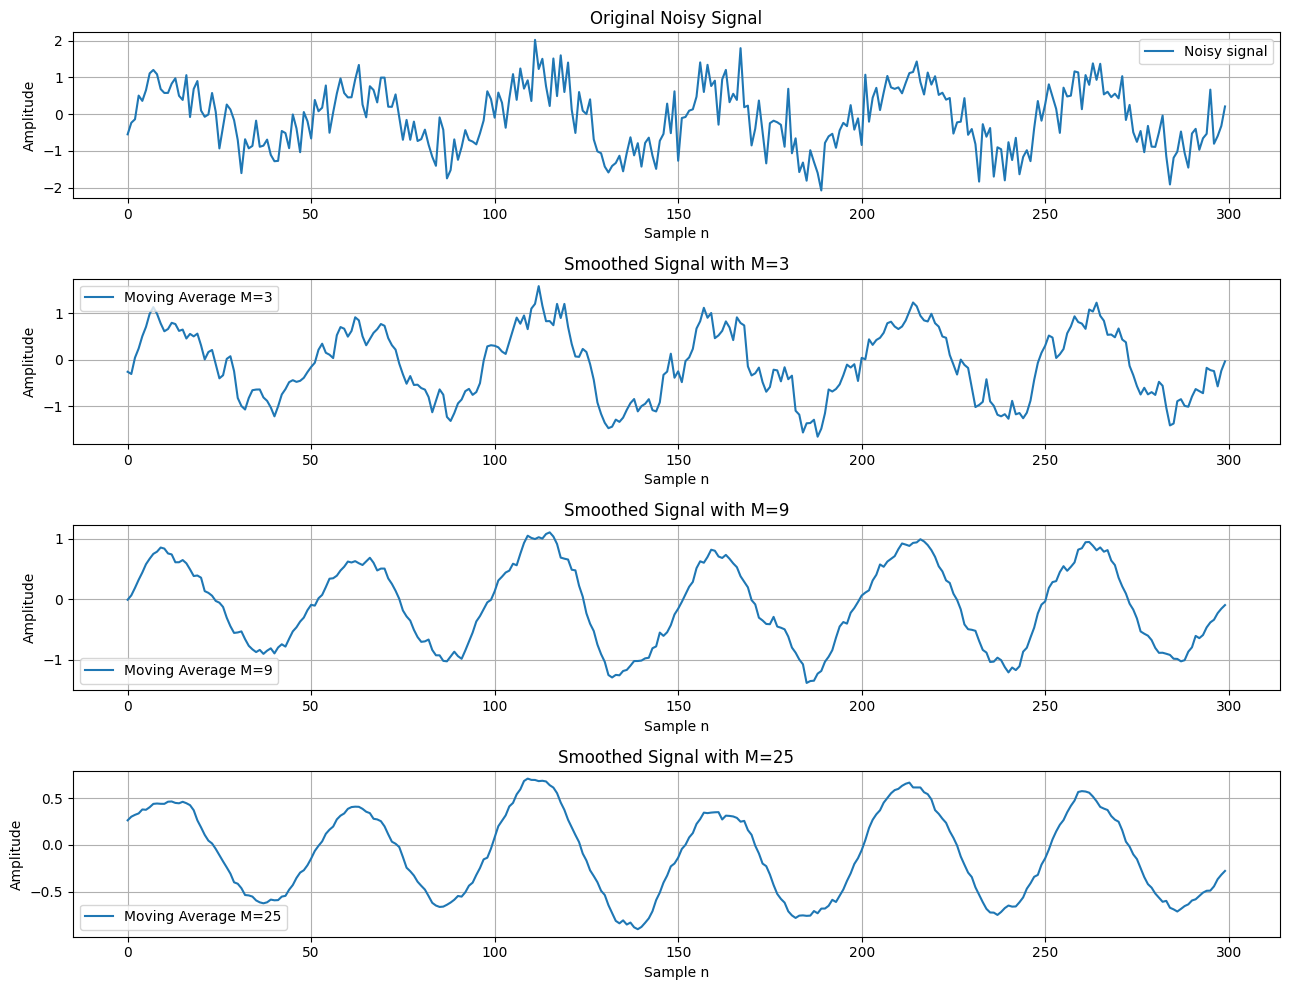

In [21]:
# ==========================================
# TASK 3.2: SMOOTHING A NOISY SIGNAL
# ==========================================

rng = np.random.default_rng(10)

n = np.arange(300)

# Generate Gaussian noise

w = rng.standard_normal(300)

# Create noisy sinusoidal signal

x = np.sin(2 * np.pi * n / 50) + 0.5 * w


# Moving average filter lengths

M_values = [3, 9, 25]


plt.figure(figsize=(13, 10))


# Original signal

plt.subplot(4, 1, 1)

plt.plot(n, x, label="Noisy signal")

plt.title("Original Noisy Signal")

plt.xlabel("Sample n")

plt.ylabel("Amplitude")

plt.legend()

plt.grid()


# Apply moving average filters

for i, M in enumerate(M_values):

    h = np.ones(M) / M

    y = np.convolve(x, h, mode="same")

    plt.subplot(4, 1, i + 2)

    plt.plot(n, y, label=f"Moving Average M={M}")

    plt.title(f"Smoothed Signal with M={M}")

    plt.xlabel("Sample n")

    plt.ylabel("Amplitude")

    plt.legend()

    plt.grid()


plt.tight_layout()

plt.show()

### Observation

The moving-average filters reduce the random noise present in the original signal.

The filter with M = 3 provides moderate noise reduction while preserving most of the original signal shape.

The filter with M = 9 provides stronger smoothing and reduces more noise.

The filter with M = 25 provides the strongest smoothing, but it also causes greater distortion because some useful variations in the original signal are removed.

Therefore, increasing the moving-average filter length improves noise reduction but may reduce the accuracy of the original signal representation.

## Task 3.3 — Testing Linearity and Time-Invariance Numerically

### Aim

To test whether different discrete-time systems satisfy the properties of linearity and time-invariance.

### Procedure

1. Generate two random input signals.
2. Define three systems: squaring system, multiplication by n, and moving-average system.
3. Test linearity using the superposition principle.
4. Test time-invariance by delaying the input and comparing the resulting output with the delayed original output.
5. Explain the results obtained.

### Explanation

A system is linear if it satisfies additivity and homogeneity.

For inputs x1 and x2 and constants a and b:

T[a*x1 + b*x2] = a*T[x1] + b*T[x2]

A system is time-invariant if delaying its input by a certain number of samples causes its output to be delayed by the same number of samples.

In [22]:
# ==========================================
# TASK 3.3: TESTING LINEARITY AND
# TIME-INVARIANCE
# ==========================================

rng = np.random.default_rng(0)

x1 = rng.standard_normal(50)

x2 = rng.standard_normal(50)

a = 2.0

b = -3.0


# Define the systems

systems = {

    "x^2": lambda x: x**2,

    "n*x(n)": lambda x: np.arange(len(x)) * x,

    "Moving Average": lambda x:
        np.convolve(x, np.ones(3)/3)[:len(x)]

}


# Test each system

for name, T in systems.items():

    # Test linearity

    left = T(a*x1 + b*x2)

    right = a*T(x1) + b*T(x2)

    linear = np.allclose(left, right)


    # Delay input by 5 samples

    xd = np.concatenate([np.zeros(5), x1])[:50]


    # Delay original output by 5 samples

    yd = np.concatenate([np.zeros(5), T(x1)])[:50]


    # Test time-invariance

    tinv = np.allclose(T(xd), yd)


    print(f"{name:15s} linear={linear} time-invariant={tinv}")

x^2             linear=False time-invariant=True
n*x(n)          linear=True time-invariant=False
Moving Average  linear=True time-invariant=True


### Explanation of Results

1. Squaring system, x^2:

The system is not linear because squaring the input does not satisfy the superposition principle.

However, it is time-invariant because delaying the input produces an equally delayed output.

2. Multiplication by n, n*x(n):

The system is linear because it satisfies the superposition principle.

However, it is not time-invariant because its output depends explicitly on the sample position n.

3. Moving-average system:

The moving-average system is linear because it satisfies the superposition principle.

It is also time-invariant because delaying the input produces the same delay in the output.

Therefore, the moving-average system is an LTI system.

## Task 3.4 — Finding a Hidden Delay with Cross-Correlation

### Aim

To estimate the time delay between a transmitted signal and a received signal using cross-correlation.

### Procedure

1. Generate a random transmitted signal.
2. Create a received signal by delaying the transmitted signal by 37 samples.
3. Add random noise to simulate a noisy communication environment.
4. Calculate cross-correlation between the transmitted and received signals.
5. Find the lag corresponding to the maximum correlation value.
6. Repeat the experiment with noise standard deviations of 1, 2 and 4.
7. Convert the estimated delay into distance using the speed of sound.

### Explanation

Cross-correlation measures the similarity between two signals at different time shifts.

The lag that produces the maximum correlation is used to estimate the delay between the transmitted and received signals.

The speed of sound is approximately 343 metres per second.

Actual delay: 37 samples
Estimated delay: 37 samples


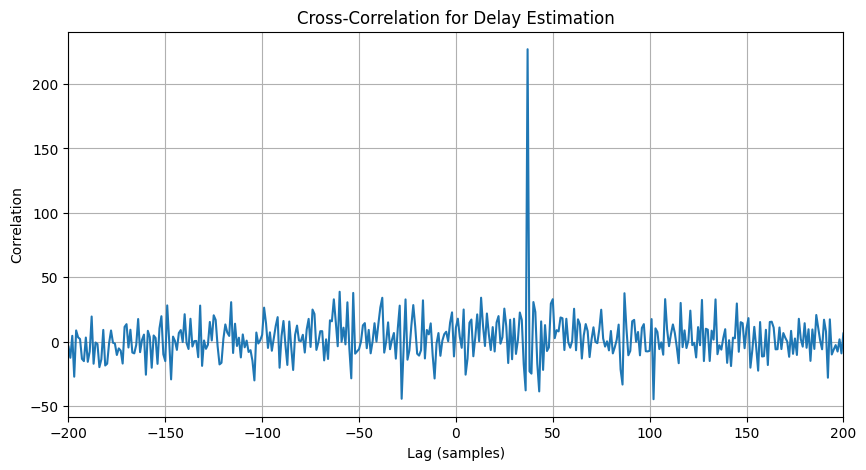

In [23]:
# ==========================================
# TASK 3.4: FINDING A HIDDEN DELAY
# ==========================================

rng = np.random.default_rng(1)

fs = 1000

# Generate transmitted signal

x = rng.standard_normal(500)

# Actual delay

true_delay = 37

# Generate received signal with noise

y = np.concatenate([np.zeros(true_delay), 0.6*x])[:500]

y = y + 0.5*rng.standard_normal(500)


# Calculate cross-correlation

r = signal.correlate(y, x, mode="full")

lags = signal.correlation_lags(
    len(y), len(x), mode="full"
)


# Estimate delay

estimated_delay = lags[np.argmax(r)]

print("Actual delay:", true_delay, "samples")

print("Estimated delay:", estimated_delay, "samples")


# Plot correlation

plt.figure(figsize=(10, 5))

plt.plot(lags, r)

plt.xlim(-200, 200)

plt.xlabel("Lag (samples)")

plt.ylabel("Correlation")

plt.title("Cross-Correlation for Delay Estimation")

plt.grid()

plt.show()

In [24]:
# ==========================================
# TEST DIFFERENT NOISE LEVELS
# ==========================================

noise_levels = [1, 2, 4]

for noise_std in noise_levels:

    # Generate received signal

    y_noisy = np.concatenate(
        [np.zeros(true_delay), 0.6*x]
    )[:500]

    y_noisy = y_noisy + noise_std*rng.standard_normal(500)


    # Calculate cross-correlation

    r_noisy = signal.correlate(
        y_noisy, x, mode="full"
    )

    lags_noisy = signal.correlation_lags(
        len(y_noisy), len(x), mode="full"
    )


    # Estimate delay

    estimated = lags_noisy[np.argmax(r_noisy)]


    print(
        "Noise standard deviation:",
        noise_std,
        "| Estimated delay:",
        estimated,
        "samples"
    )

Noise standard deviation: 1 | Estimated delay: 37 samples
Noise standard deviation: 2 | Estimated delay: 37 samples
Noise standard deviation: 4 | Estimated delay: 37 samples


In [25]:
# ==========================================
# CONVERT DELAY INTO DISTANCE
# ==========================================

speed_of_sound = 343

delay_seconds = estimated_delay / fs

distance = speed_of_sound * delay_seconds


print("Estimated delay:", estimated_delay, "samples")

print("Sampling frequency:", fs, "Hz")

print("Delay in seconds:", delay_seconds, "seconds")

print("Estimated distance:", distance, "metres")

Estimated delay: 37 samples
Sampling frequency: 1000 Hz
Delay in seconds: 0.037 seconds
Estimated distance: 12.690999999999999 metres


### Observation

Cross-correlation successfully estimated the delay between the transmitted and received signals.

The actual delay was 37 samples, and the estimated delay was also 37 samples.

When noise was added to the received signal, the correlation peak was still detectable in this experiment.

The estimated delay was 0.037 seconds.

Using the speed of sound of 343 m/s, the estimated distance was approximately 12.691 metres.

Cross-correlation is therefore useful in applications such as radar, sonar, GPS and sound-based distance measurement.

In [26]:
# ==========================================
# TASK 3.5: DIRECT RECURSION
# ==========================================

# Create unit impulse

N = 10

impulse = np.zeros(N)

impulse[0] = 1


# Initialize output

h_direct = np.zeros(N)


# Calculate impulse response

for n in range(N):

    x_n = impulse[n]

    x_previous = impulse[n-1] if n >= 1 else 0

    y_previous = h_direct[n-1] if n >= 1 else 0

    y_previous2 = h_direct[n-2] if n >= 2 else 0


    h_direct[n] = (
        x_n
        + x_previous
        + 0.75*y_previous
        - 0.125*y_previous2
    )


print("Impulse response using direct recursion:")

print(h_direct)

Impulse response using direct recursion:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]


In [27]:
# ==========================================
# IMPULSE RESPONSE USING SCIPY LFILTER
# ==========================================

b = [1, 1]

a = [1, -0.75, 0.125]


h_lfilter = signal.lfilter(
    b, a, impulse
)


print("Impulse response using lfilter:")

print(h_lfilter)

Impulse response using lfilter:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]


In [28]:
# ==========================================
# COMPARE WITH CLOSED-FORM EXPRESSION
# ==========================================

n = np.arange(10)


h_closed = (
    6*(0.5**n)
    - 5*(0.25**n)
)


print("Direct recursion:")

print(h_direct)


print("\nlfilter result:")

print(h_lfilter)


print("\nClosed-form result:")

print(h_closed)


print("\nDirect recursion equals lfilter:")

print(np.allclose(h_direct, h_lfilter))


print("\nlfilter equals closed-form:")

print(np.allclose(h_lfilter, h_closed))

Direct recursion:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]

lfilter result:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]

Closed-form result:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]

Direct recursion equals lfilter:
True

lfilter equals closed-form:
True


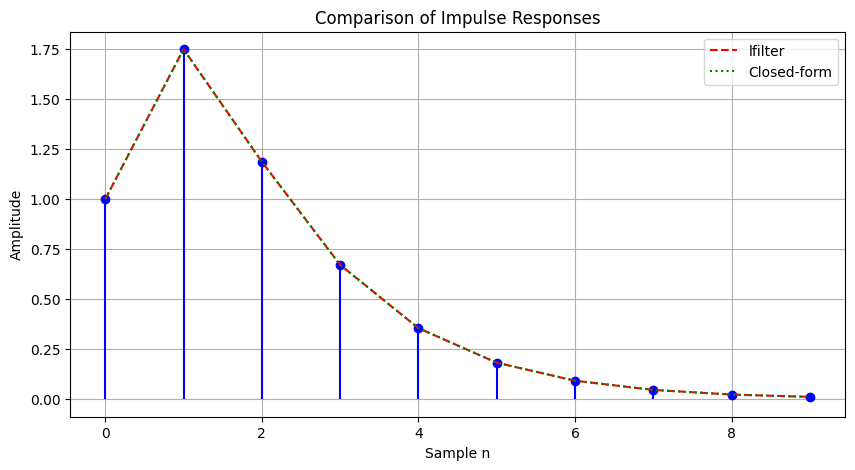

In [29]:
# ==========================================
# PLOT THREE IMPULSE RESPONSES
# ==========================================

plt.figure(figsize=(10, 5))


plt.stem(
    np.arange(10),
    h_direct,
    linefmt="b-",
    markerfmt="bo",
    basefmt=" "
)


plt.plot(
    np.arange(10),
    h_lfilter,
    "r--",
    label="lfilter"
)


plt.plot(
    np.arange(10),
    h_closed,
    "g:",
    label="Closed-form"
)


plt.title("Comparison of Impulse Responses")

plt.xlabel("Sample n")

plt.ylabel("Amplitude")

plt.legend()

plt.grid()

plt.show()

Final step response value:
5.333333333333333


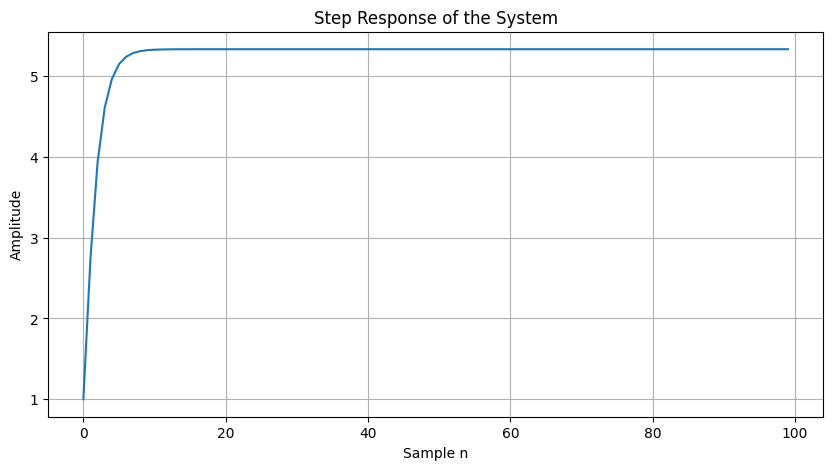

In [30]:
# ==========================================
# CALCULATE STEP RESPONSE
# ==========================================

N = 100

# Generate unit step

step = np.ones(N)


# Apply difference equation

step_response = signal.lfilter(
    b, a, step
)


# Calculate final value

final_value = step_response[-1]


print("Final step response value:")

print(final_value)


# Plot step response

plt.figure(figsize=(10, 5))

plt.plot(step_response)

plt.title("Step Response of the System")

plt.xlabel("Sample n")

plt.ylabel("Amplitude")

plt.grid()

plt.show()

In [31]:
# ==========================================
# CALCULATE H(1)
# ==========================================

H1 = sum(b) / sum(a)


print("Sum of numerator coefficients:", sum(b))

print("Sum of denominator coefficients:", sum(a))

print("H(1):", H1)

print("Final step response:", final_value)

Sum of numerator coefficients: 2
Sum of denominator coefficients: 0.375
H(1): 5.333333333333333
Final step response: 5.333333333333333


### Observation

The impulse response was calculated using direct recursion, the SciPy lfilter function and the closed-form expression.

All three methods produced matching results, confirming that the difference equation was implemented correctly.

The step response approached a final value of approximately 5.3333.

The calculated value of H(1) was also approximately 5.3333.

Therefore, the final step response agrees with the theoretical DC gain of the system.

# 5. Analysis Questions and Answers

## Question 1

Why is np.convolve so much faster than your double loop? What is the number of multiplications for lengths L and M?

### Answer

The np.convolve function is faster because it uses an optimized implementation of convolution, while the manual method uses Python nested loops.

For two sequences of lengths L and M, the number of multiplications required by direct convolution is approximately:

L * M

The manual implementation performs these operations using Python loops, which increases execution time.

NumPy uses optimized low-level routines, making convolution faster, especially for large sequences.

## Question 2

Which of the three systems in Task 3.3 are LTI? Could you have predicted this without running code?

### Answer

The three systems are:

1. Squaring system, x^2:
   - Nonlinear because it does not satisfy the superposition principle.
   - Time-invariant because delaying the input produces an equally delayed output.
   - Therefore, it is not an LTI system.

2. Multiplication by n, n*x(n):
   - Linear because it satisfies the superposition principle.
   - Time-varying because the output depends explicitly on n.
   - Therefore, it is not an LTI system.

3. Moving-average system:
   - Linear because it satisfies the superposition principle.
   - Time-invariant because delaying the input produces the same delay in the output.
   - Therefore, it is an LTI system.

Yes, these properties could be predicted mathematically using the definitions of linearity and time-invariance without running the program.

## Question 3

Give two engineering applications of cross-correlation in Tanzania.

### Answer

Two engineering applications of cross-correlation in Tanzania include:

1. Locating water pipe leaks:

Water utilities can use signals from sensors placed along water pipes. Cross-correlation can estimate the time difference between signals detected by different sensors, helping engineers locate the position of a leak.

2. GPS and navigation systems:

GPS receivers use correlation to identify satellite signals and estimate signal arrival times. These timing measurements help determine the receiver's position.

Other applications include radar systems used in airport monitoring and communication systems.

## Question 4

Is the system in Task 3.5 FIR or IIR? Stable? Justify from the impulse response.

### Answer

The system is an Infinite Impulse Response (IIR) system because its output depends on previous output samples as well as input samples.

The impulse response continues beyond the first few samples and gradually approaches zero.

The system is stable because its impulse response is absolutely summable and its poles are inside the unit circle.

The poles are:

0.5 and 0.25

Both poles have magnitudes less than 1.

Therefore, the system is a stable IIR system.

# 6. AI-Use Statement

AI tools used: ChatGPT

Used for:

Understanding convolution, correlation, system properties and difference equations, as well as explaining Python errors and suggesting code structure.

How I verified the output:

I compared the manually calculated convolution with NumPy's convolve function. I compared the impulse responses obtained through direct recursion, SciPy lfilter and the closed-form expression. I also checked the estimated delay against the known delay of 37 samples and compared the final step response with H(1).
